In [1]:
import sys
sys.path.append('..')
import pandas as pd
from src.db import read_sql
from src.cleaning import load_clean_orders
from src.impact import run_scenarios

df = load_clean_orders()
aov = df['payment_total'].mean()
test = pd.read_csv('../data/processed/test_scores.csv')   # held-out customers only
res = run_scenarios(test, aov, top_pct=0.2)
res.to_csv('../data/processed/impact_scenarios.csv', index=False)
print('Average order value used: R$', round(aov, 2), ' | test customers:', len(test))
res

Average order value used: R$ 159.85  | test customers: 11181


,customers_targeted,expected_baseline_repeat_orders,incremental_orders,incremental_revenue,coupon_cost,net_benefit,roi,scenario
0,2236,82.9,4.1,663.0,870.0,-208.0,-0.24,conservative
1,2236,82.9,8.3,1325.0,912.0,413.0,0.45,base
2,2236,82.9,16.6,2650.0,995.0,1655.0,1.66,optimistic


targeted share (20%), coupon value (R$10), uplift per scenario (5/10/20%), AOV used, margin used, and the limitation that high predicted probability does not mean the coupon will change behavior.

In [2]:
orders = read_sql('SELECT * FROM vw_orders_clean')   # raw view keeps missing review scores as blank
orders['state_country'] = orders['customer_state'] + ', Brazil'
orders['delay_bucket'] = pd.cut(orders['delivery_delay_days'], bins=[-999, 0, 3, 7, 999],
                                labels=['On time or early', 'Late 1-3 days', 'Late 4-7 days', 'Late 7+ days']).astype(str)
orders.to_csv('../dashboard/orders.csv', index=False)
read_sql('SELECT order_id, category, price FROM vw_items_clean').to_csv('../dashboard/items.csv', index=False)
pd.read_csv('../data/processed/customer_rfm.csv').to_csv('../dashboard/rfm.csv', index=False)
pd.read_csv('../data/processed/customer_risk_scores.csv').drop(columns='segment').to_csv('../dashboard/scores.csv', index=False)
res.to_csv('../dashboard/impact.csv', index=False)

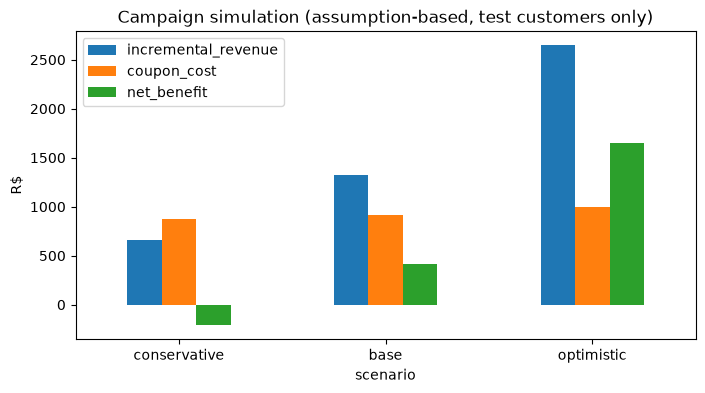

In [3]:
import matplotlib.pyplot as plt
res.set_index('scenario')[['incremental_revenue', 'coupon_cost', 'net_benefit']].plot(kind='bar', figsize=(8, 4), title='Campaign simulation (assumption-based, test customers only)')
plt.ylabel('R$'); plt.xticks(rotation=0)
plt.savefig('../reports/figures/impact_scenarios.png', dpi=150, bbox_inches='tight')
plt.show()